⏳ Đang tải dữ liệu ETHUSDT khung 4h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest RSI + Median Price Breakout Strategy...

METRICS (RSI + Median Price Breakout)
     Final Equity: 14016.3374
     Total Return: 0.4016
    CAGR (approx): 0.1515
     Max Drawdown: -0.1148
           Sharpe: 1.4142
           Trades: 195
          Winrate: 0.4923
    Avg PnL/Trade: 20.5966
    Profit Factor: 1.4283
           Max DD: -0.114811977095


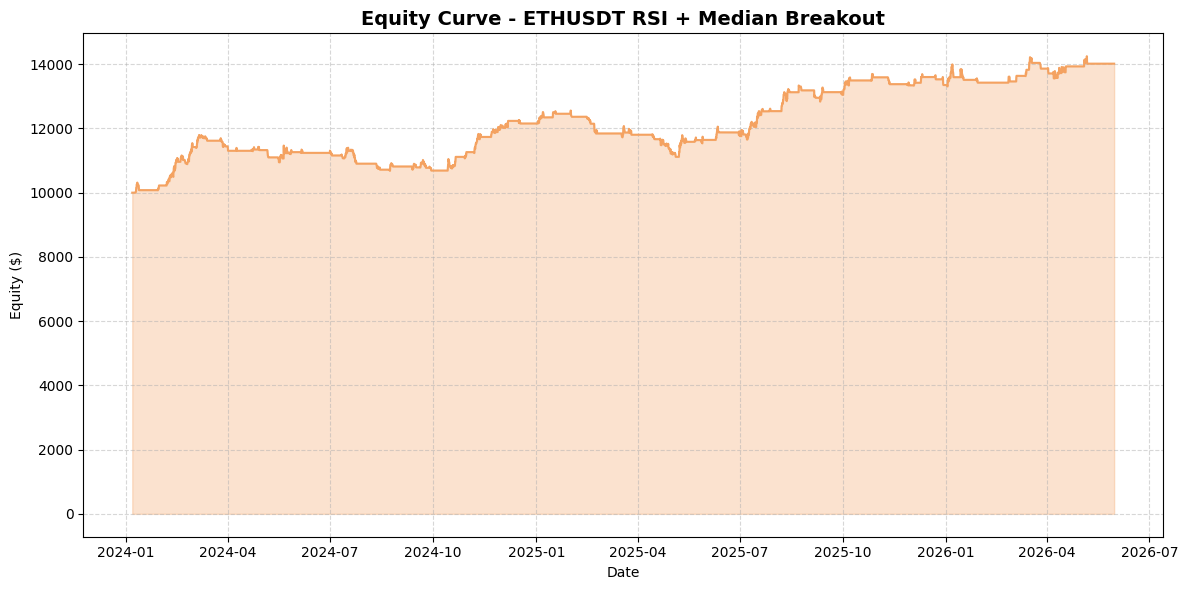


📊 Sample Trades (first 10):
            Exit Time  Type     Entry         Exit         PnL         Reason       Balance
0 2024-01-10 08:00:00  LONG  2341.575  2417.704753  133.408394    Take Profit  10133.408394
1 2024-01-10 20:00:00  LONG  2449.300  2535.880739  128.472593    Take Profit  10261.880987
2 2024-01-11 16:00:00  LONG  2613.000  2587.900000  -28.799094  Trailing Stop  10233.081894
3 2024-01-12 20:00:00  LONG  2647.580  2514.430000 -154.368670  Trailing Stop  10078.713224
4 2024-01-30 16:00:00  LONG  2295.025  2359.554740  145.707613    Take Profit  10224.420837
5 2024-02-07 16:00:00  LONG  2337.275  2394.036926  143.642505    Take Profit  10368.063342
6 2024-02-09 08:00:00  LONG  2425.090  2482.683499  141.696240    Take Profit  10509.759581
7 2024-02-12 12:00:00  LONG  2495.330  2554.698625  139.784942    Take Profit  10649.544524
8 2024-02-13 00:00:00  LONG  2610.250  2671.018363  139.639832    Take Profit  10789.184356
9 2024-02-14 08:00:00  LONG  2660.980  2729.145858 

In [6]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Median Price = (High + Low) / 2
    data['Median_Price'] = (data['High'] + data['Low']) / 2
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    
    # RSI(20) on Close
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_20'] = calc_rsi(data['Close'], 20)
    
    # Highest/Lowest Median Price trong 37 nến
    data['Highest_Median_37'] = data['Median_Price'].rolling(window=37).max()
    data['Lowest_Median_37'] = data['Median_Price'].rolling(window=37).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class RSIMedianBreakoutBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        self.trailing_sl = None
        
        # Strategy Parameters
        self.risk_pct = 0.02  # 2%
        self.sl_coef = 3.0  # SL = 3.0 * ATR(20)
        self.tp_coef = 2.0  # TP = 2.0 * ATR(30)
        self.trailing_stop = 70  # Fixed pips/ticks
        self.exit_after_bars = 38
        self.pending_expiration = 3
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check Trailing Stop first
                    if self.trailing_sl is not None and current_bar['Low'] <= self.trailing_sl:
                        self.close_position(self.trailing_sl, idx, "Trailing Stop")
                        self.append_equity(idx)
                        continue
                    
                    # Check SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # Check TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop (activation = 0, trail immediately)
                    new_trailing_sl = current_bar['Close'] - self.trailing_stop
                    
                    if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                        self.trailing_sl = new_trailing_sl
                        # Update main SL if trailing is better
                        self.sl = max(self.sl, self.trailing_sl)
                
                elif self.position == 'SHORT':
                    # Check Trailing Stop first
                    if self.trailing_sl is not None and current_bar['High'] >= self.trailing_sl:
                        self.close_position(self.trailing_sl, idx, "Trailing Stop")
                        self.append_equity(idx)
                        continue
                    
                    # Check SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # Check TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop (activation = 0, trail immediately)
                    new_trailing_sl = current_bar['Close'] + self.trailing_stop
                    
                    if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                        self.trailing_sl = new_trailing_sl
                        # Update main SL if trailing is better
                        self.sl = min(self.sl, self.trailing_sl)
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=1
                if i < 1:
                    self.append_equity(idx)
                    continue
                
                # RSI Filter (shift=1)
                rsi_shift1 = self.df.iloc[i-1]['RSI_20']
                
                # Long Signal: RSI < 95 (almost always true)
                long_signal = rsi_shift1 < 95
                
                # Short Signal: RSI > 5 (but only when !long_signal)
                # Effectively: RSI >= 95
                short_signal = rsi_shift1 > 5
                
                if not long_signal and not short_signal:
                    self.append_equity(idx)
                    continue
                
                # Entry parameters (shift=1)
                highest_median_shift1 = self.df.iloc[i-1]['Highest_Median_37']
                lowest_median_shift1 = self.df.iloc[i-1]['Lowest_Median_37']
                
                # SL/TP parameters (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]['ATR_20']
                atr_30_shift1 = self.df.iloc[i-1]['ATR_30']
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_median_shift1
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_30_shift1
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    # Short only when RSI >= 95
                    entry_price = lowest_median_shift1
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_30_shift1
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Reset trailing
        self.trailing_sl = None
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0
        self.trailing_sl = None

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (RSI + Median Price Breakout)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print(f"           Max DD: {metrics['Max Drawdown']:.12f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#F4A261')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#F4A261')
    
    plt.title(f"Equity Curve - {symbol} RSI + Median Breakout", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "4h"
    start_date = "01/01/2024"
    end_date = "30/05/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Đang chạy Backtest RSI + Median Price Breakout Strategy...")
        bt = RSIMedianBreakoutBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
            
            print("\n📊 Long vs Short Distribution:")
            print(trades_df['Type'].value_counts())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")